# Data Cleaning: HDB Resale Prices and Property Information

This notebook profiles the two HDB datasets in `../data/` and checks them for quality problems before analysis:

1. `ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv`: one row per resale transaction, Jan 2017–Sep 2026
2. `HDBPropertyInformation.csv`: one row per HDB block, with building attributes and unit mix

For each dataset:
- check the raw file's structure and text formatting
- profile the numeric columns
- check the unit, the time coverage and perform reasonableness checks
- flag suspicious values

Then check how the two datasets relate (join keys, town codes, lease vs completion year) and summarise the issues.

Post-review, apply the necessary fixes and save the cleaned data as new files in `data/` (with the suffix `_clean`). The original files are not changed.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)

DATA_DIR = '../data'
RESALE_PATH = f'{DATA_DIR}/ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv'
PROP_PATH = f'{DATA_DIR}/HDBPropertyInformation.csv'
RESALE_CLEAN_PATH = f'{DATA_DIR}/ResaleflatpricesbasedonregistrationdatefromJan2017onwards_clean.csv'
PROP_CLEAN_PATH = f'{DATA_DIR}/HDBPropertyInformation_clean.csv'

In [2]:
# Chart style: light background, quiet grid and axes, one blue for the data
INK, INK_2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, BLUE_LIGHT = '#2a78d6', '#b7d3f6'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True,
    'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'font.size': 9, 'figure.dpi': 110, 'figure.titlesize': 12, 'figure.titleweight': 'bold',
})
THOUSANDS = FuncFormatter(lambda x, _: f'{x:,.0f}')


def hist_panel(ax, s, title, bins=40):
    """Draw a histogram of one numeric column on chart panel `ax`, with a dashed line and label at the median.
    Use it to see the shape of a field at a glance: whether it is skewed, has several peaks, or has outliers.
    Missing values are left out."""
    s = s.dropna()
    ax.hist(s, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    med = s.median()
    ax.axvline(med, color=INK_2, linewidth=1, linestyle='--')
    ax.annotate(f'median {med:,.0f}', xy=(med, 1), xycoords=('data', 'axes fraction'),
                xytext=(4, -2), textcoords='offset points', va='top', fontsize=8, color=INK_2)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.set_ylabel('rows')


def box_by_group(ax, df, value, group, title, order=None):
    """Draw one box plot per group in `group` (e.g. per flat type) for the numeric column `value`, side by side on chart panel `ax`.
    Each box shows the middle 50% of values, the dark line is the median, and grey dots are outliers beyond 1.5 x the box height.
    Use it to compare how a metric differs across groups."""
    groups = order or sorted(df[group].unique())
    data = [df.loc[df[group] == g, value].dropna() for g in groups]
    ax.boxplot(data, patch_artist=True, widths=0.55,
               boxprops=dict(facecolor=BLUE_LIGHT, edgecolor=BLUE, linewidth=1),
               medianprops=dict(color=INK, linewidth=1.5),
               whiskerprops=dict(color=BLUE, linewidth=1), capprops=dict(color=BLUE, linewidth=1),
               flierprops=dict(marker='o', markersize=2, markerfacecolor=MUTED, markeredgecolor='none', alpha=0.4))
    ax.set_xticks(range(1, len(groups) + 1), groups)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(THOUSANDS)

In [3]:
def text_profile(df, num_cols=()):
    """Count formatting problems in each column of a file read entirely as text, before pandas converts any types.
    It reports nulls, blanks, distinct values, stray spaces, mixed case and the number of text patterns (digits -> N, letters -> A),
    and for columns in `num_cols` it counts values that are not valid numbers. Use it to find what needs cleaning before loading with proper types."""
    rows = []
    for col in df.columns:
        s = df[col]
        row = {
            'column': col,
            'nulls': s.isna().sum(),
            'empty': (s.str.strip() == '').sum(),
            'distinct': s.nunique(),
            'leading/trailing ws': (s != s.str.strip()).sum(),
            'not all upper': (s != s.str.upper()).sum(),
            'patterns': s.str.replace(r'\d+', 'N', regex=True).str.replace(r'[A-Za-z]+', 'A', regex=True).nunique(),
        }
        if col in num_cols:
            row['not a number'] = (~s.str.fullmatch(r'-?\d+(\.\d+)?').fillna(False)).sum()
        rows.append(row)
    return pd.DataFrame(rows).set_index('column')


def numeric_profile(df, cols):
    """Summarise the spread of each numeric column in `cols`: count, mean, min, max and percentiles from 1% to 99%.
    It also counts zeros and negatives and reports skew, which helps flag impossible values
    and shows whether the median is a better 'typical' value than the mean."""
    out = df[cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
    out['zeros'] = (df[cols] == 0).sum()
    out['negatives'] = (df[cols] < 0).sum()
    out['skew'] = df[cols].skew()
    return out

---
## 1. HDB Resale Transactions

### 1.1 Raw text checks
Ingest every column as text to view formatting problems (blanks, whitespace, mixed formats).

In [4]:
# read raw resale file as text
resale_raw = pd.read_csv(RESALE_PATH, dtype=str)
print(resale_raw.shape)
resale_raw.head()

(241148, 11)


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44,Improved,1979,61 years 04 months,232000
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67,New Generation,1978,60 years 07 months,250000
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,262000
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68,New Generation,1980,62 years 01 month,265000
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67,New Generation,1980,62 years 05 months,265000


In [5]:
# profile the raw resale file to see what needs cleaning
text_profile(resale_raw, num_cols=['floor_area_sqm', 'lease_commence_date', 'resale_price'])

,nulls,empty,distinct,leading/trailing ws,not all upper,patterns,not a number
column,,,,,,,
month,0,0,117,0,0,1,NaN
town,0,0,26,0,0,4,NaN
flat_type,0,0,7,0,0,3,NaN
block,0,0,2783,0,0,1,NaN
street_name,0,0,580,0,0,10,NaN
storey_range,0,0,17,0,0,1,NaN
floor_area_sqm,0,0,352,0,0,2,0.0
flat_model,0,0,21,0,237331,5,NaN
lease_commence_date,0,0,58,0,0,1,0.0


- There are no missing values/nulls, empty strings or stray whitespaces in any of the 11 columns.
- `floor_area_sqm`, `lease_commence_date` and `resale_price` are all valid numbers.
- `flat_model` (e.g. `Model A`, `Improved`) and `remaining_lease` (`years`, `months`) are in mixed case, while the other text fields are upper case. This is fine as long as we don't join on them.
- `remaining_lease` has **more than one text pattern**, so it is checked below.

In [6]:
# remaining_lease: how many different text formats are there?
resale_raw['remaining_lease'].str.replace(r'\d+', 'N', regex=True).value_counts()

remaining_lease
N years N months    201851
N years              19794
N years N month      19503
Name: count, dtype: int64

- `remaining_lease` is stored as text in **3 formats**: `N years N months` (201,851 rows), `N years` (19,794 rows, where months is 0) and `N years N month` (19,503 rows, where months is 1). It **needs to be parsed into a number** (e.g. total months) before it can be used in any analysis.

In [7]:
# floor_area_sqm: share of values written with decimals, by year
resale_raw['floor_area_sqm'].str.contains('.', regex=False).groupby(resale_raw['month'].str[:4]).mean().rename('share with decimals')

month
2017    0.000536
2018    0.000371
2019    0.000451
2020    0.000814
2021    0.000550
2022    1.000000
2023    1.000000
2024    1.000000
2025    1.000000
2026    1.000000
Name: share with decimals, dtype: float64

- `floor_area_sqm` is written as whole numbers (`44`) until 2021 and with decimals (`151.00`) from 2022. The values read correctly as numbers, but it shows the **source format changed in 2022**, so a few post-2022 areas have real decimals (e.g. `100.2`) that earlier years would have rounded.

In [8]:
# storey_range: all values should look like 'NN TO NN'
print('Well-formed storey_range:', resale_raw['storey_range'].str.fullmatch(r'\d{2} TO \d{2}').all())
sorted(resale_raw['storey_range'].unique())

Well-formed storey_range: True


['01 TO 03',
 '04 TO 06',
 '07 TO 09',
 '10 TO 12',
 '13 TO 15',
 '16 TO 18',
 '19 TO 21',
 '22 TO 24',
 '25 TO 27',
 '28 TO 30',
 '31 TO 33',
 '34 TO 36',
 '37 TO 39',
 '40 TO 42',
 '43 TO 45',
 '46 TO 48',
 '49 TO 51']

- All 17 storey bands are well-formed and 3 floors wide, from `01 TO 03` up to `49 TO 51`. The exact floor isn't available, so the first number of each band can be used to order them.

### 1.2 Load with the correct types

Read `block` as text, because block numbers include letters (e.g. `999A`). Parse `month` into a date and convert `remaining_lease` into total months.

In [9]:
# update the data types
resale = pd.read_csv(RESALE_PATH, dtype={'block': str})
resale['date'] = pd.to_datetime(resale['month'], format='%Y-%m') #parse month to datetime, so we can group by year and month easily

# '61 years 04 months' = 61 * 12 + 4 = 736 months
lease = resale['remaining_lease'].str.extract(r'(\d+) years?(?: (\d+) months?)?').astype(float)
resale['remaining_lease_months'] = (lease[0] * 12 + lease[1].fillna(0)).astype(int)
resale['remaining_lease_years'] = resale['remaining_lease_months'] / 12

NUM = ['floor_area_sqm', 'lease_commence_date', 'remaining_lease_years', 'resale_price']
resale.dtypes

month                                str
town                                 str
flat_type                            str
block                                str
street_name                          str
storey_range                         str
floor_area_sqm                   float64
flat_model                           str
lease_commence_date                int64
remaining_lease                      str
resale_price                     float64
date                      datetime64[us]
remaining_lease_months             int64
remaining_lease_years            float64
dtype: object

In [10]:
# check counts and share of transactions for each dimension
def counts_with_share(s):
    """Count the rows for each value of `s` and add each value's share of all rows, largest first.
    Used to see which groups dominate the data and which are too small to analyse reliably."""
    counts = s.value_counts()
    return pd.DataFrame({'count': counts, 'share': (counts / counts.sum()).map('{:.1%}'.format)})

display(counts_with_share(resale['flat_type']))
display(counts_with_share(resale['town']))

,count,share
flat_type,,
4 ROOM,102489,42.5%
5 ROOM,58996,24.5%
3 ROOM,57282,23.8%
EXECUTIVE,17137,7.1%
2 ROOM,5066,2.1%
MULTI-GENERATION,90,0.0%
1 ROOM,88,0.0%


,count,share
town,,
SENGKANG,19501,8.1%
PUNGGOL,17441,7.2%
WOODLANDS,17170,7.1%
TAMPINES,16733,6.9%
YISHUN,16362,6.8%
JURONG WEST,15791,6.5%
BEDOK,12584,5.2%
HOUGANG,12178,5.1%
CHOA CHU KANG,10821,4.5%


- **4 ROOM** flats make up **42.5%** of all transactions (102,489), followed by 5 ROOM (24.5%) and 3 ROOM (23.8%). Together these three types are over 90% of the market. **1 ROOM (88) and MULTI-GENERATION (90)** are each less than 0.1%, so statistics on them won't be reliable.
- There are 26 towns. The largest by volume are newer towns: Sengkang (8.1%), Punggol (7.2%) and Woodlands (7.1%) together make up about 22% of all transactions. **Bukit Timah has only 588 transactions (0.2%)**, so its median price can move a lot from just a few sales.

### 1.3 Unit and time coverage

The expected unit is one row per resale transaction. There is **no transaction ID**, so no column (or combination of columns) is guaranteed to be unique.

In [11]:
# check for duplicate rows
print('Exact duplicate rows (excluding first copy):', resale_raw.duplicated().sum())
# check the maximum number of copies for any single row
print('Max copies of one row:', resale_raw.groupby(list(resale_raw.columns)).size().max())

# How common is it for several flats with identical attributes to sell in the same month?
key = [c for c in resale_raw.columns if c != 'resale_price']
same_attrs = resale_raw.groupby(key)['resale_price'].agg(['size', 'nunique'])
same_attrs = same_attrs[same_attrs['size'] > 1]
print('Groups of identical flats sold in the same month:', len(same_attrs))
print('  ... sold at different prices:', (same_attrs['nunique'] == same_attrs['size']).sum())
print('  ... with at least one repeated price:', (same_attrs['nunique'] < same_attrs['size']).sum())

dups = resale_raw[resale_raw.duplicated(keep=False)]
dups.groupby(dups['month'].str[:4]).size().rename('duplicate rows (all copies) by year')

Exact duplicate rows (excluding first copy): 318
Max copies of one row: 3


Groups of identical flats sold in the same month: 3049
  ... sold at different prices: 2732
  ... with at least one repeated price: 317


month
2017    344
2018     18
2019     36
2020     40
2021     60
2022     36
2023     28
2024     30
2025     25
2026     18
Name: duplicate rows (all copies) by year, dtype: int64

- There are **318 exact duplicate rows**, with at most 2–3 copies of a row.
- These are not necessarily errors. There are 3,049 cases where flats with identical attributes (same block, storey band, size, model and lease) sold in the same month, and 2,732 of them sold at *different* prices. So two neighbouring flats selling in the same month is common, and some will land on the same round price (97% of duplicate rows end in `000`).
- However, the duplicates are **concentrated in 2017** (344 of 635 duplicate rows) and drop to about 20–60 a year after that. That pattern fits a one-off loading issue better than random coincidence.
- **Decision:** keep the duplicates (they are 0.1% of rows and can't be confirmed as errors) but note it as a known issue. Re-check the 2017 rows against HDB's resale portal if the 2017 numbers matter for a finding.

In [12]:
# check the date range and whether there are any missing months
print('Date range:', resale['month'].min(), 'to', resale['month'].max())
print('Is the file sorted by month?', resale['month'].is_monotonic_increasing)

all_months = pd.period_range(resale['month'].min(), resale['month'].max(), freq='M').astype(str)
missing = sorted(set(all_months) - set(resale['month']))
print(f'Months in range: {len(all_months)}, months present: {resale["month"].nunique()}')
print('Missing months:', missing)

Date range: 2017-01 to 2026-09
Is the file sorted by month? False


Months in range: 117, months present: 117
Missing months: []


- The data runs from **Jan 2017 to Sep 2026** with no missing months. 2026 is a partial year (9 months).
- **The file is not sorted by month**, so sort it before any time-series work.

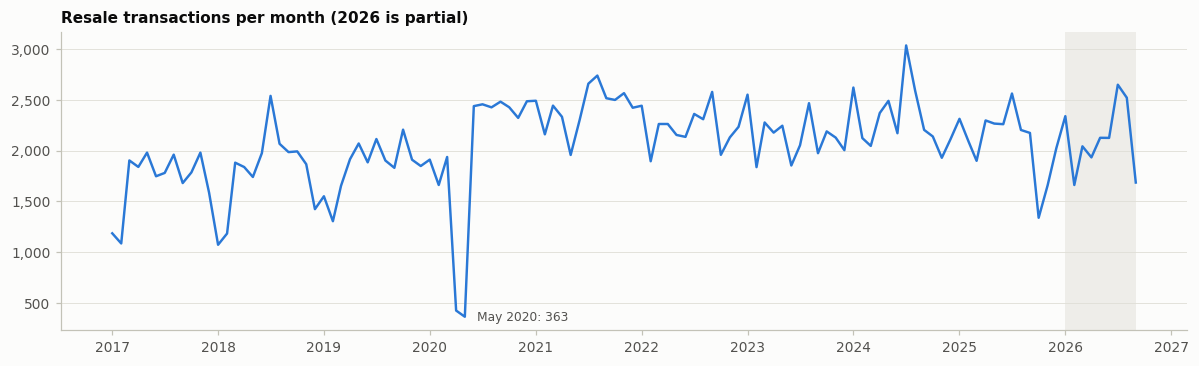

date
2017    20509
2018    21561
2019    22186
2020    23333
2021    29087
2022    26720
2023    25754
2024    27832
2025    25085
2026    19081
Name: rows per year, dtype: int64

In [13]:
# Transactions per month. The last year is partial, so it is shaded.
monthly = resale.groupby('date').size()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.axvspan(pd.Timestamp('2026-01-01'), monthly.index.max(), color=GRID, alpha=0.5, linewidth=0)
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=1.6)
low = monthly.idxmin()
ax.annotate(f'{low:%b %Y}: {monthly.min():,}', xy=(low, monthly.min()), xytext=(8, 0),
            textcoords='offset points', va='center', fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_title('Resale transactions per month (2026 is partial)')
fig.tight_layout()
plt.show()

resale.groupby(resale['date'].dt.year).size().rename('rows per year')

- Monthly volume is usually between about 1,650 and 2,500 (median 2,114). The **lowest months are Apr–May 2020 (424 and 363)**, during the COVID-19 "circuit breaker", when flat viewings and transactions were restricted. Unlike a missing month, these are real, very low months, so watch for them in any month-on-month comparison.
- Volume **jumped in 2021 (29,087)**, the highest year, and has stayed above 2017–2020 levels since.
- 2026 has 19,081 rows for 9 months, so **yearly totals will make 2026 look low**. Compare quarters or matching periods (e.g. Jan–Sep vs Jan–Sep).
- `month` is the **registration** month, which is usually 1–2 months after the price is agreed. The most recent months may still be filling in.

### 1.4 Numeric profile

In [14]:
# check the distribution of numeric columns, to see if there are any impossible values or outliers
numeric_profile(resale, NUM).round(1)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,zeros,negatives,skew
floor_area_sqm,241148.0,96.7,24.0,31.0,47.0,63.0,81.0,93.0,112.0,142.0,151.0,366.7,0,0,0.3
lease_commence_date,241148.0,1996.6,14.4,1966.0,1969.0,1975.0,1985.0,1997.0,2012.0,2018.0,2020.0,2023.0,0,0,0.1
remaining_lease_years,241148.0,74.1,14.3,39.3,45.8,51.8,62.2,73.8,88.5,94.8,95.2,97.8,0,0,-0.0
resale_price,241148.0,535398.6,192667.7,140000.0,235000.0,280000.0,390000.0,505000.0,642000.0,900000.0,1100000.0,1728000.0,0,0,1.0


- There are no zeros or negative values in any numeric column.
- `resale_price` ranges from **S\$140K to S\$1.728M**, with a median of S\$505K and a mean of S\$535K. It is **right-skewed (0.97)**: a long tail of expensive flats pulls the mean up, so the **median is the better "typical" price**.
- `floor_area_sqm` ranges from 31 to 366.7 sqm. The 99th percentile is 151 sqm, so the maximum is far above the rest and is checked in 1.6.
- `lease_commence_date` runs from 1966 to 2023, so the oldest flats sold had just under 40 years left on the lease (39 years 4 months), and the newest flats (just past the 5-year Minimum Occupation Period) had up to 97 years 9 months.

In [15]:
# Row holding the min and max of each metric
COLS = ['month', 'town', 'flat_type', 'block', 'street_name', 'storey_range', 'floor_area_sqm', 'flat_model', 'remaining_lease', 'resale_price']
extremes = []
for col in ['floor_area_sqm', 'remaining_lease_years', 'resale_price']:
    for label, idx in [('min', resale[col].idxmin()), ('max', resale[col].idxmax())]:
        extremes.append({'metric': col, 'stat': label, **resale.loc[idx, COLS].to_dict()})
pd.DataFrame(extremes)

,metric,stat,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price
0,floor_area_sqm,min,2017-03,BUKIT MERAH,1 ROOM,7,TELOK BLANGAH CRES,01 TO 03,31.0,Improved,57 years,200000.0
1,floor_area_sqm,max,2024-07,KALLANG/WHAMPOA,3 ROOM,53,JLN MA'MOR,01 TO 03,366.7,Terrace,47 years,1568000.0
2,remaining_lease_years,min,2026-08,JURONG EAST,3 ROOM,37,TEBAN GDNS RD,01 TO 03,67.0,Improved,39 years 04 months,320000.0
3,remaining_lease_years,max,2020-08,BUKIT MERAH,3 ROOM,96A,HENDERSON RD,10 TO 12,68.0,Model A,97 years 09 months,612000.0
4,resale_price,min,2020-02,TOA PAYOH,3 ROOM,26,TOA PAYOH EAST,10 TO 12,67.0,Improved,49 years 11 months,140000.0
5,resale_price,max,2026-04,BUKIT MERAH,5 ROOM,96A,HENDERSON RD,46 TO 48,113.0,Improved,92 years 01 month,1728000.0


- The cheapest flat was a **3 ROOM in Toa Payoh in Feb 2020 at S\$140K**, and the most expensive a **5 ROOM at Henderson Rd (Bukit Merah) in Apr 2026 at S\$1.728M** on floors 46–48.
- The smallest flats are 1 ROOM units at 31 sqm, and the largest is a 366.7 sqm "3 ROOM" Terrace flat, which is investigated in 1.6.

#### Distribution charts

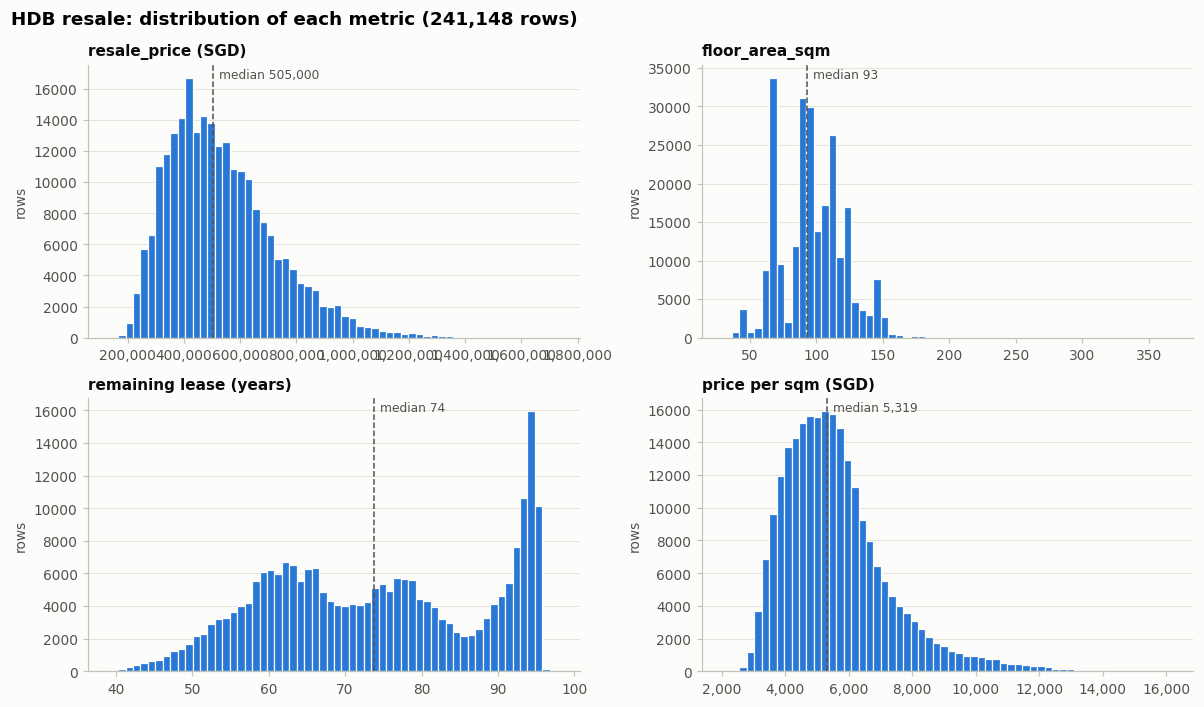

In [16]:
# Histograms of each metric, to understand distribution, skew, outliers, etc. 
resale['price_per_sqm'] = resale['resale_price'] / resale['floor_area_sqm']
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (col, title) in zip(axes.flat, [('resale_price', 'resale_price (SGD)'), ('floor_area_sqm', 'floor_area_sqm'),
                                        ('remaining_lease_years', 'remaining lease (years)'), ('price_per_sqm', 'price per sqm (SGD)')]):
    hist_panel(ax, resale[col], title, bins=60)
fig.suptitle(f'HDB resale: distribution of each metric ({len(resale):,} rows)', x=0.01, ha='left')
fig.tight_layout()
plt.show()

- `resale_price` has a long right tail of flats above S\$1M.
- `floor_area_sqm` has **several peaks** because each flat type has standard sizes (about 67 sqm for 3 ROOM, 93 for 4 ROOM, 110–120 for 5 ROOM).
- `remaining_lease` has two bumps: older flats with **55–70 years** left (built in the late 1970s–1980s), and the single largest group, flats with **90–95 years** left (49,108 sales), which are newer flats just past their Minimum Occupation Period. Fewer than 2,000 sales have under 45 years left, so comparisons across lease bands should check the group sizes.
- `price_per_sqm` (price divided by area) is more symmetric than price, which makes it a better measure for comparing flats of different sizes.

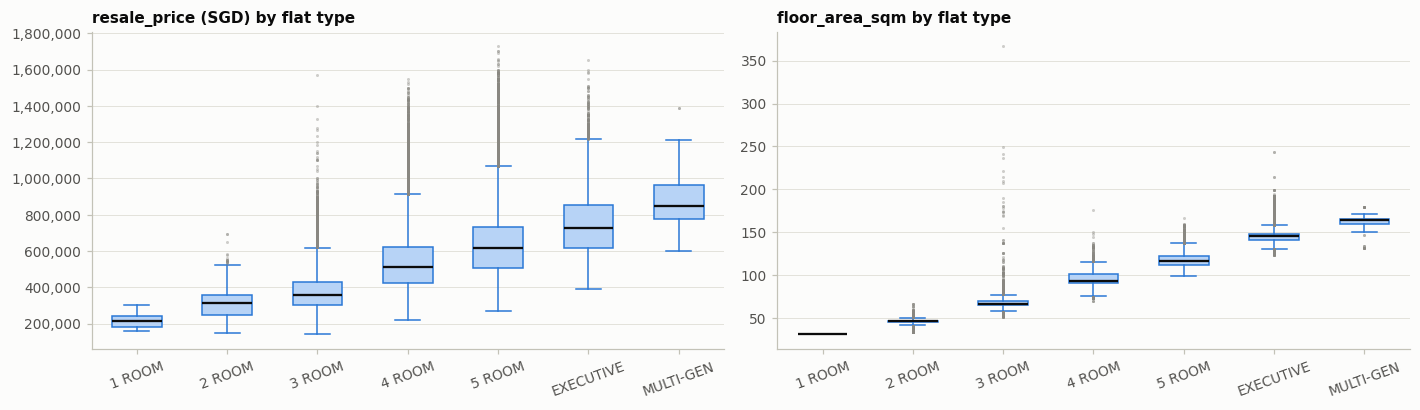

,floor_area_sqm,resale_price
flat_type,,
1 ROOM,31.0,212500.0
2 ROOM,47.0,315000.0
3 ROOM,67.0,360000.0
4 ROOM,93.0,512000.0
5 ROOM,117.0,615000.0
EXECUTIVE,146.0,728888.0
MULTI-GENERATION,164.0,849000.0


In [17]:
# Price and area by flat type. The box is the middle 50%, the dark line is the median, and grey dots are outliers beyond 1.5 × the box height.
ORDER = ['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE', 'MULTI-GENERATION']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
box_by_group(axes[0], resale, 'resale_price', 'flat_type', 'resale_price (SGD) by flat type', ORDER)
box_by_group(axes[1], resale, 'floor_area_sqm', 'flat_type', 'floor_area_sqm by flat type', ORDER)
for ax in axes:
    ax.set_xticks(range(1, len(ORDER) + 1), [o.replace('MULTI-GENERATION', 'MULTI-GEN') for o in ORDER], rotation=20)
fig.tight_layout()
plt.show()

resale.groupby('flat_type')[['floor_area_sqm', 'resale_price']].median().loc[ORDER]

- The median price rises steadily with flat type, from **S\$212.5K for 1 ROOM to S\$849K for MULTI-GENERATION**, which is what we'd expect.
- Within each flat type the price range is wide and overlaps heavily with the next type. A large 4 ROOM in a central town can cost more than a typical 5 ROOM, so **flat type alone doesn't explain price**. Location and lease will matter.
- Floor area is tightly grouped within each type, except for a few very large **3 ROOM** flats. These are looked at in 1.6.

### 1.5 Reasonableness checks
- `remaining_lease` should be close to 99 years minus the years since `lease_commence_date`.
- Each `block` + `street_name` should have one `lease_commence_date`.
- `floor_area_sqm` should fall within a sensible range for each flat type.

In [18]:
# Expected remaining lease = 99 - (years from lease start to sale month)
sale_year = resale['date'].dt.year + (resale['date'].dt.month - 1) / 12
expected = 99 - (sale_year - resale['lease_commence_date'])
resale['lease_gap'] = resale['remaining_lease_years'] - expected

print('remaining_lease vs the 99-year formula (years):')
print(resale['lease_gap'].describe().round(2).to_string())
print()
print('Rows more than 2 years off:', (resale['lease_gap'].abs() > 2).sum())
print('Blocks with more than one lease_commence_date:',
      (resale.groupby(['block', 'street_name'])['lease_commence_date'].nunique() > 1).sum())

remaining_lease vs the 99-year formula (years):
count    241148.00
mean          0.50
std           0.29
min         -14.92
25%           0.25
50%           0.50
75%           0.75
max           1.50

Rows more than 2 years off: 1
Blocks with more than one lease_commence_date: 1


- `remaining_lease` matches the 99-year formula for almost every row. The gap is between 0 and 1.5 years, with a median of 0.5, because the lease starts partway through the `lease_commence_date` year (only the year is given).
- **Only 1 row is more than 2 years off (by about 15 years)**, and only 1 block has more than one `lease_commence_date`. These are likely the same row and are investigated later in 1.6.

In [19]:
resale.groupby('flat_type')['floor_area_sqm'].describe(percentiles=[.01, .5, .99]).loc[ORDER].round(1)

,count,mean,std,min,1%,50%,99%,max
flat_type,,,,,,,,
1 ROOM,88.0,31.0,0.0,31.0,31.0,31.0,31.0,31.0
2 ROOM,5066.0,45.7,3.4,34.0,37.0,47.0,54.0,67.0
3 ROOM,57282.0,68.1,6.3,51.0,56.0,67.0,88.0,366.7
4 ROOM,102489.0,95.0,6.9,70.0,82.0,93.0,112.0,176.0
5 ROOM,58996.0,117.7,7.3,99.0,107.0,117.0,139.0,167.0
EXECUTIVE,17137.0,144.8,10.5,124.0,125.0,146.0,184.0,243.0
MULTI-GENERATION,90.0,161.3,12.9,132.0,132.0,164.0,179.0,179.0


- Each flat type sits in a tight band of sizes, except **3 ROOM**: the 99th percentile is 88 sqm but the maximum is 366.7 sqm, which is larger than any Executive flat. That needs an explanation before it's used in 3 ROOM comparisons.

### 1.6 Suspicious values

#### Lease outlier: Block 37 Teban Gardens Rd

In [20]:
# All sales in the block with the lease outlier
teban = resale[(resale['block'] == '37') & (resale['street_name'] == 'TEBAN GDNS RD')]
teban[['month', 'flat_type', 'storey_range', 'lease_commence_date', 'remaining_lease', 'resale_price', 'lease_gap']].round(1)

,month,flat_type,storey_range,lease_commence_date,remaining_lease,resale_price,lease_gap
482,2017-01,3 ROOM,04 TO 06,1966,48 years 09 months,250000.0,0.8
15850,2017-10,3 ROOM,01 TO 03,1966,48 years,200000.0,0.8
17680,2017-11,3 ROOM,01 TO 03,1966,48 years,232000.0,0.8
28989,2018-06,3 ROOM,01 TO 03,1966,47 years 04 months,226000.0,0.8
35570,2018-09,3 ROOM,01 TO 03,1966,47 years 02 months,215000.0,0.8
64988,2020-01,3 ROOM,04 TO 06,1966,45 years 09 months,220000.0,0.8
86084,2020-12,3 ROOM,01 TO 03,1966,44 years 10 months,230000.0,0.8
179946,2024-05,3 ROOM,01 TO 03,1966,41 years 06 months,340000.0,0.8
206482,2025-01,3 ROOM,04 TO 06,1981,40 years 01 month,350000.0,-14.9
206496,2025-06,3 ROOM,04 TO 06,1966,40 years 05 months,360000.0,0.8


- Block 37 Teban Gardens Rd has 12 resales. **Eleven have `lease_commence_date` = 1966, and one (Jan 2025) has 1981.**
- That row's `remaining_lease` of 40 years 1 month fits a 1966 lease, which is consistent with the other sales in the same block. So the **`lease_commence_date` of 1981 is the wrong value**, and the remaining lease is correct.

**Action:** set `lease_commence_date` to 1966 for this row, based on the other 11 sales in the same block. Since `remaining_lease` is the column used for lease analysis, the impact on analysis is small either way.

#### Very large flats: Terrace units

In [21]:
# The largest flats: errors or real?
resale[resale['floor_area_sqm'] > 200][COLS]

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price
8868,2017-06,KALLANG/WHAMPOA,3 ROOM,38,JLN BAHAGIA,01 TO 03,215.0,Terrace,54 years 01 month,830000.0
13950,2017-09,CHOA CHU KANG,EXECUTIVE,641,CHOA CHU KANG ST 64,16 TO 18,215.0,Premium Maisonette,79 years 04 months,888000.0
19693,2017-12,KALLANG/WHAMPOA,3 ROOM,65,JLN MA'MOR,01 TO 03,249.0,Terrace,53 years 07 months,1053888.0
20828,2018-01,CHOA CHU KANG,EXECUTIVE,639,CHOA CHU KANG ST 64,10 TO 12,215.0,Premium Maisonette,79 years,900000.0
35797,2018-09,KALLANG/WHAMPOA,3 ROOM,41,JLN BAHAGIA,01 TO 03,237.0,Terrace,52 years 10 months,1185000.0
92512,2021-03,BISHAN,EXECUTIVE,446,BRIGHT HILL DR,07 TO 09,243.0,Maisonette,68 years 01 month,1092888.0
94959,2021-04,BISHAN,EXECUTIVE,454,SIN MING AVE,10 TO 12,243.0,Maisonette,67 years 08 months,1001000.0
95808,2021-04,KALLANG/WHAMPOA,3 ROOM,61,JLN TENTERAM,01 TO 03,222.0,Terrace,50 years 03 months,1100000.0
100088,2021-06,KALLANG/WHAMPOA,3 ROOM,39,JLN BAHAGIA,01 TO 03,210.0,Terrace,50 years 01 month,1268000.0
107851,2021-09,KALLANG/WHAMPOA,3 ROOM,46,JLN BAHAGIA,01 TO 03,241.0,Terrace,49 years 10 months,1235000.0


In [22]:
terrace = resale[resale['flat_model'] == 'Terrace']
print('Terrace sales:', len(terrace), '| flat types:', terrace['flat_type'].unique().tolist(),
      '| towns:', terrace['town'].unique().tolist())
print('Terrace floor area (sqm):', terrace['floor_area_sqm'].describe().round(0)[['min', '50%', 'max']].to_dict())

Terrace sales: 123 | flat types: ['3 ROOM', '4 ROOM'] | towns: ['KALLANG/WHAMPOA', 'QUEENSTOWN']
Terrace floor area (sqm): {'min': 78.0, '50%': 98.0, 'max': 367.0}


- All the very large "3 ROOM" flats are **Terrace** flats in Kallang/Whampoa (e.g. Jln Bahagia, Jln Ma'mor). These are rare, landed-style HDB units from the 1970s with their own land area. That explains the sizes (up to 366.7 sqm) and the S\$1M+ prices, so **they are real, not data errors**.
- There are 123 Terrace sales in total: 101 in Kallang/Whampoa and 22 in Queenstown (Stirling Rd), labelled 3 ROOM (116) or 4 ROOM (7). Most are a normal size (median 98 sqm), but 19 are above 150 sqm. Either way, they aren't comparable to typical 3 ROOM or 4 ROOM flats.
- The two **Executive Premium Maisonettes in Choa Chu Kang (215 sqm)** and the **Executive Maisonettes in Bishan (243 sqm)** are also unusually large but within what that flat model allows.

**Action:** keep them but add an `is_terrace` flag, and exclude them from 3 ROOM and 4 ROOM price and price-per-sqm comparisons.

#### Prices far from comparable flats

In [23]:
# Compare each sale's price per sqm with the median for the same town, flat type and year.
# A ratio far below 1 means the flat sold much cheaper than comparable flats.
grp = [resale['town'], resale['flat_type'], resale['date'].dt.year]
resale['psm_vs_peers'] = resale['price_per_sqm'] / resale.groupby(grp)['price_per_sqm'].transform('median')
print('Sales below 0.5x their peers:', (resale['psm_vs_peers'] < 0.5).sum())
print('Sales above 2x their peers:', (resale['psm_vs_peers'] > 2).sum())
resale.nsmallest(6, 'psm_vs_peers')[COLS + ['psm_vs_peers']].round(2)

Sales below 0.5x their peers: 33
Sales above 2x their peers: 236


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price,psm_vs_peers
163898,2023-08,TAMPINES,3 ROOM,522A,TAMPINES CTRL 7,07 TO 09,67.0,Model A,91 years 03 months,150000.0,0.39
211974,2025-01,QUEENSTOWN,4 ROOM,23B,QUEEN'S CL,07 TO 09,89.0,Improved,47 years 05 months,400000.0,0.42
233723,2026-08,QUEENSTOWN,4 ROOM,23,DOVER CRES,01 TO 03,88.0,Improved,48 years 11 months,450000.0,0.44
167182,2023-12,WOODLANDS,2 ROOM,182A,WOODLANDS ST 13,28 TO 30,47.0,Model A,94 years 11 months,150000.0,0.45
238306,2026-07,TOA PAYOH,4 ROOM,227,LOR 8 TOA PAYOH,04 TO 06,82.0,Improved,48 years 11 months,410000.0,0.45
238307,2026-07,TOA PAYOH,4 ROOM,220,LOR 8 TOA PAYOH,01 TO 03,82.0,Improved,49 years,410000.0,0.45


- Only 33 sales are priced below half of their peers (same town, flat type and year). Most are old flats with under 50 years of lease left in central towns such as Queenstown and Toa Payoh. That fits lease decay rather than a data error.
- The 236 sales above 2x their peers are mostly the Terrace flats and Pinnacle@Duxton units at the top end. These are real.
- Two rows stand out because they are **young flats sold for exactly S\$150K**: Block 522A Tampines Central 7 (ratio 0.39, the lowest of all) and Block 182A Woodlands St 13 (0.45). Old flats are expected to be cheap, but young ones aren't, so each is checked against the other sales in its own block below. Within one block, location, age and lease are the same, so the comparison is fair.

In [24]:
# The lowest one: the most recent 3 ROOM sales in the same block
tamp = resale[(resale['block'] == '522A') & (resale['street_name'] == 'TAMPINES CTRL 7') & (resale['flat_type'] == '3 ROOM')]
print(tamp['resale_price'].describe().round(0).to_string())
tamp.sort_values('date')[['month', 'storey_range', 'floor_area_sqm', 'flat_model', 'remaining_lease', 'resale_price']].iloc[18:26]

count        31.0
mean     456983.0
std       85273.0
min      150000.0
25%      412500.0
50%      450000.0
75%      511500.0
max      620000.0


,month,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price
138287,2022-10,04 TO 06,67.0,Model A,91 years 11 months,480000.0
138431,2022-11,04 TO 06,67.0,Model A,91 years 10 months,485100.0
138596,2022-12,10 TO 12,67.0,Model A,91 years 09 months,523000.0
162975,2023-01,16 TO 18,67.0,Model A,91 years 07 months,518000.0
163271,2023-03,13 TO 15,67.0,Model A,91 years 05 months,530000.0
163898,2023-08,07 TO 09,67.0,Model A,91 years 03 months,150000.0
164315,2023-11,04 TO 06,67.0,Model A,90 years 09 months,505000.0
190357,2024-01,01 TO 03,67.0,Model A,90 years 08 months,500000.0


- Block 522A Tampines Central 7 has 31 sales of the same 67 sqm Model A 3 ROOM flat. Leaving out the Aug 2023 sale, they range from **S\$380K to S\$620K**.
- The sales just before and after it were **S\$530K (Mar 2023) and S\$505K (Nov 2023)**, so the market didn't drop in between.
- Floor height doesn't explain it either: the other sales on the **same floors (07–09)** went for S\$385K–520K.

**Conclusion:** S\$150K is less than a third of what the same flat sold for in the same year. It is **not a real market price**. It's either a typing error (e.g. a missing digit) or a non-market transfer (e.g. between family members).

In [25]:
# Check the second outlier the same way
wdl = resale[(resale['block'] == '182A') & (resale['street_name'] == 'WOODLANDS ST 13') & (resale['flat_type'] == '2 ROOM')]
print(wdl['resale_price'].describe().round(0).to_string())
wdl.sort_values('date')[['month', 'storey_range', 'floor_area_sqm', 'flat_model', 'remaining_lease', 'resale_price']].head(4)

count        20.0
mean     367458.0
std       56249.0
min      150000.0
25%      363750.0
50%      374944.0
75%      392791.0
max      423000.0

,month,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price
167182,2023-12,28 TO 30,47.0,Model A,94 years 11 months,150000.0
167190,2023-12,10 TO 12,47.0,Model A,94 years 11 months,350000.0
193105,2024-01,10 TO 12,47.0,Model A,94 years 10 months,330000.0
193113,2024-01,22 TO 24,38.0,Model A,94 years 11 months,360000.0


- Block 182A Woodlands St 13 has 20 sales of 2 ROOM flats (38 or 47 sqm). Leaving out the Dec 2023 sale, they range from **S\$330K to S\$423K**, and the median is S\$375K.
- In the **same month**, a 47 sqm flat on floors 10–12 sold for **S\$350K**, more than twice the S\$150K sale of the same size on floors 28–30.
- The other sales on the **same floors (28–30)** went for S\$380K–413K, so the high floor makes S\$150K even less plausible, not more.

**Conclusion:** same as Tampines. S\$150K is about 40% of the block's typical price, for a flat with 95 years of lease left. It is **not a real market price**.

**Treatment for both rows:**
- **Set `resale_price` to missing (`NaN`)** in the cleaned file. We can't tell what the true price was, so it can't be corrected.
- **Keep the rows.** The flat type, size, lease and location are still valid, so they still count towards transaction volumes. Only the price is removed.
- **Don't impute** (e.g. with the block median). An imputed price saved in the cleaned file would look exactly like a real one, and no one would know it was a guess.

### 1.7 Round-number bias
Prices ending in `000` usually come from buyers and sellers choosing round numbers. Prices ending in `888` are "lucky" numbers in Chinese culture. Both are expected and less likely to be a data problem.

In [26]:
p = resale['resale_price']
print(f"resale_price ends in 000: {(p % 1000 == 0).mean():.1%}")
print(f"resale_price ends in 888: {(p % 1000 == 888).mean():.1%}")
(p % 1000 == 888).groupby(resale['date'].dt.year).mean().map('{:.1%}'.format).rename('share ending in 888')

resale_price ends in 000: 92.1%
resale_price ends in 888: 5.7%


date
2017    3.6%
2018    3.6%
2019    3.4%
2020    3.7%
2021    4.8%
2022    5.5%
2023    6.3%
2024    7.9%
2025    8.9%
2026    8.4%
Name: share ending in 888, dtype: str

- **92% of prices end in `000`**, so prices are clearly negotiated round figures, not exact valuations.
- **5.7% of prices end in `888`** (e.g. S\$728,888, S\$1,688,888), and this share has **more than doubled from 3.6% in 2017 to 8.9% in 2025**. The rise in "lucky" pricing coincides with the rise in prices, which suggests sellers use it more as prices climb.
- Medians will often land on these values (e.g. the EXECUTIVE median of S\$728,888).

In [27]:
# Prices that are not whole dollars
cents = resale_raw[resale_raw['resale_price'].str.contains('.', regex=False)]
print('Prices with cents:', len(cents))
print('... ending in .88:', cents['resale_price'].str.endswith('.88').sum())
cents[['month', 'town', 'flat_type', 'block', 'street_name', 'resale_price']].head(8)

Prices with cents: 67
... ending in .88: 57


,month,town,flat_type,block,street_name,resale_price
3468,2017-03,QUEENSTOWN,3 ROOM,55,STIRLING RD,888888.88
4537,2017-04,BUKIT MERAH,5 ROOM,111A,DEPOT RD,725888.88
4828,2017-04,HOUGANG,4 ROOM,701,HOUGANG AVE 2,390088.88
5039,2017-04,JURONG WEST,5 ROOM,987C,JURONG WEST ST 93,470088.88
18141,2017-11,PUNGGOL,5 ROOM,176D,EDGEFIELD PLAINS,408888.88
34168,2018-08,SENGKANG,4 ROOM,450A,SENGKANG WEST WAY,430488.88
35123,2018-09,BUKIT BATOK,EXECUTIVE,142,BT BATOK ST 11,615779.75
36210,2018-09,SENGKANG,4 ROOM,434B,FERNVALE RD,448008.88


- **67 prices include cents**, and 57 of them end in `.88` (e.g. S\$888,888.88, and S\$1,388,888.88 at Pinnacle@Duxton). These are lucky-number prices taken to the last digit, so they are **real, not errors**.
- It means `resale_price` can't be stored as an integer. Keep it as a decimal number; rounding would change real values for no benefit.

### 1.8 Relationships between columns

In [28]:
# Correlation between numeric columns (Pearson). Correlation does not imply causation.
resale[['floor_area_sqm', 'lease_commence_date', 'remaining_lease_years', 'resale_price']].corr().round(2)

,floor_area_sqm,lease_commence_date,remaining_lease_years,resale_price
floor_area_sqm,1.00,0.09,0.10,0.56
lease_commence_date,0.09,1.00,0.98,0.38
remaining_lease_years,0.10,0.98,1.00,0.30
resale_price,0.56,0.38,0.30,1.00


- `floor_area_sqm` has the strongest relationship with price (0.56). Bigger flats cost more, as expected.
- `remaining_lease_years` (0.30) and `lease_commence_date` (0.38) are only moderately related to price **across all flats**. This doesn't mean lease doesn't matter: older flats are concentrated in central, mature towns where prices are higher, so location hides some of the lease effect. That needs to be checked **within** each town and flat type during analysis.
- `lease_commence_date` and `remaining_lease_years` are **0.98 correlated** because one is derived from the other. Use only one of them in any model.

---
## 2. HDB Property Information

### 2.1 Raw text checks

In [29]:
# read raw property file as text
prop_raw = pd.read_csv(PROP_PATH, dtype=str)
print(prop_raw.shape)
num_cols = [c for c in prop_raw.columns if c not in ('blk_no', 'street', 'bldg_contract_town') and prop_raw[c].str.fullmatch(r'\d+').all()]
text_profile(prop_raw, num_cols=num_cols)

(13357, 24)


,nulls,empty,distinct,leading/trailing ws,not all upper,patterns,not a number
column,,,,,,,
blk_no,0,0,3437,0,0,1,NaN
street,0,0,657,0,0,10,NaN
max_floor_lvl,0,0,46,0,0,1,0.0
year_completed,0,0,71,0,0,1,0.0
residential,0,0,2,0,0,1,NaN
commercial,0,0,2,0,0,1,NaN
market_hawker,0,0,2,0,0,1,NaN
miscellaneous,0,0,2,0,0,1,NaN
multistorey_carpark,0,0,2,0,0,1,NaN


- There are no missing values/nulls, empty strings or stray whitespaces in any of the 24 columns, and all text is upper case.
- All 15 count and year columns contain whole numbers only.
- The six Y/N columns each have exactly 2 distinct values, so there are no stray codes such as `y`, `Yes` or blanks.

In [30]:
prop = pd.read_csv(PROP_PATH, dtype={'blk_no': str})
FLAGS = ['residential', 'commercial', 'market_hawker', 'miscellaneous', 'multistorey_carpark', 'precinct_pavilion']
UNIT_COLS = [c for c in prop.columns if c.endswith('_sold') or c.endswith('_rental')]
pd.DataFrame({'Y count': (prop[FLAGS] == 'Y').sum(), 'Y rate': (prop[FLAGS] == 'Y').mean().map('{:.1%}'.format)})

,Y count,Y rate
residential,10796,80.8%
commercial,2526,18.9%
market_hawker,107,0.8%
miscellaneous,3147,23.6%
multistorey_carpark,1125,8.4%
precinct_pavilion,933,7.0%


- **81% of blocks are residential** (10,796). The other 2,561 are non-residential structures that HDB manages, such as car parks, markets and commercial blocks.
- 18.9% of blocks have commercial space, and only 107 blocks (0.8%) have a market or hawker centre.
- The Y/N values are stored as text. Convert them to True/False before analysis.

### 2.2 Unit and coverage
The expected unit is one row per block, identified by `blk_no` × `street`.

In [31]:
print('Duplicate (blk_no, street):', prop.duplicated(['blk_no', 'street']).sum())
print('Distinct blk_no:', prop['blk_no'].nunique(), '| distinct streets:', prop['street'].nunique())
print('Town codes:', prop['bldg_contract_town'].nunique())
print('year_completed range:', prop['year_completed'].min(), 'to', prop['year_completed'].max())

Duplicate (blk_no, street): 0
Distinct blk_no: 3437 | distinct streets: 657
Town codes: 27
year_completed range: 1937 to 2026


- Every block is unique on `blk_no` + `street`. `blk_no` alone is not unique: block numbers are reused across streets (e.g. there are 36 blocks numbered `1`), so **always join on both columns**.
- Blocks were completed between **1937 and 2026**. There are 27 town codes, one more than the 26 towns in the resale data, because the property file also covers Tengah (`TG`), a new town with no resales yet.

### 2.3 Numeric profile

In [32]:
numeric_profile(prop, ['max_floor_lvl', 'year_completed', 'total_dwelling_units'] + UNIT_COLS).round(1)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,zeros,negatives,skew
max_floor_lvl,13357.0,12.1,7.2,1.0,1.0,1.0,6.0,12.0,16.0,25.0,38.0,50.0,0,0,0.8
year_completed,13357.0,1995.8,15.5,1937.0,1963.0,1974.0,1984.0,1994.0,2008.0,2023.0,2025.0,2026.0,0,0,0.1
total_dwelling_units,13357.0,88.0,66.6,0.0,0.0,0.0,32.0,91.0,120.0,197.0,290.0,584.0,2561,0,0.9
1room_sold,13357.0,0.0,2.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,253.0,13355,0,86.3
2room_sold,13357.0,4.0,19.1,0.0,0.0,0.0,0.0,0.0,0.0,21.0,110.0,234.0,12534,0,5.7
3room_sold,13357.0,18.8,43.7,0.0,0.0,0.0,0.0,0.0,8.0,118.0,196.0,528.0,9854,0,3.2
4room_sold,13357.0,35.1,41.0,0.0,0.0,0.0,0.0,24.0,59.0,114.2,160.4,316.0,5204,0,1.4
5room_sold,13357.0,19.8,29.7,0.0,0.0,0.0,0.0,0.0,40.0,84.0,100.0,164.0,7576,0,1.4
exec_sold,13357.0,4.8,16.9,0.0,0.0,0.0,0.0,0.0,0.0,50.0,84.0,135.0,11651,0,3.8
multigen_sold,13357.0,0.0,1.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,66.0,13349,0,46.4


- `max_floor_lvl` ranges from 1 to 50 storeys, with a median of 12.
- `total_dwelling_units` has **2,561 zeros**, exactly the number of non-residential blocks.
- The unit-count columns are **mostly zeros** and heavily skewed (e.g. `1room_sold` is zero for 13,355 of 13,357 blocks), because each block usually has only one or two flat types.
- The oldest blocks, completed in 1937, are at Tiong Bahru (Tiong Bahru Rd and Eng Hoon St). They were built by HDB's predecessor, the Singapore Improvement Trust, and are still in use.

### 2.4 Reasonableness checks
- Sold + rental units should add up to `total_dwelling_units`.
- Non-residential blocks should have no dwelling units, and residential blocks should have some.
- `year_completed` should not be in the future.
- `year_completed` should not be implausibly old (checked separately below).

In [33]:
print('Sold + rental != total_dwelling_units:', (prop[UNIT_COLS].sum(axis=1) != prop['total_dwelling_units']).sum())
print('Residential = N but has dwelling units:', ((prop['residential'] == 'N') & (prop['total_dwelling_units'] > 0)).sum())
print('Residential = Y but no dwelling units:', ((prop['residential'] == 'Y') & (prop['total_dwelling_units'] == 0)).sum())
print('year_completed after 2026:', (prop['year_completed'] > 2026).sum())

Sold + rental != total_dwelling_units: 0
Residential = N but has dwelling units: 0
Residential = Y but no dwelling units: 0
year_completed after 2026: 0


- All checks pass: unit counts always add up, the residential flag always agrees with the unit counts, and there are no future completion years.
- This file is clean and needs no value changes. Its main limitation is that it's a **snapshot of today**: a block's attributes (e.g. rental units) may have been different when older sales happened.

#### Oldest blocks: is `year_completed` plausibly old?

The check above rules out future years. This one checks the other end: a suspiciously early year can be a placeholder for "unknown" (e.g. `1900`). HDB was set up in **1960**, so any older block needs an explanation.

In [34]:
# Distribution of the earliest completion years, and where the pre-1960 blocks are
print('Earliest completion years (year: blocks):', prop['year_completed'].value_counts().sort_index().head(8).to_dict())

pre_hdb = prop[prop['year_completed'] < 1960]
print(f'Blocks completed before 1960: {len(pre_hdb)} ({len(pre_hdb) / len(prop):.1%} of all blocks)')
pre_hdb.groupby('street').agg(blocks=('blk_no', 'size'), first_year=('year_completed', 'min'),
                              last_year=('year_completed', 'max'), residential=('residential', lambda s: (s == 'Y').sum()))

Earliest completion years (year: blocks): {1937: 28, 1938: 2, 1949: 30, 1958: 8, 1959: 35, 1961: 3, 1962: 27, 1963: 42}
Blocks completed before 1960: 103 (0.8% of all blocks)


,blocks,first_year,last_year,residential
street,,,,
CHAY YAN ST,2,1937,1937,2
DAKOTA CRES,5,1958,1958,5
ENG HOON ST,3,1937,1937,3
ENG WATT ST,2,1937,1937,2
GUAN CHUAN ST,2,1937,1937,2
JLN BAHAGIA,17,1959,1959,17
JLN MA'MOR,10,1959,1959,10
JLN TENTERAM,1,1959,1959,1
KIM CHENG ST,4,1949,1949,4


- No placeholder years. The earliest is **1937**.
- **103 blocks (0.8%) are older than HDB (1937–1959).** All are in estates built by HDB's predecessor, the Singapore Improvement Trust (SIT): Tiong Bahru, Whampoa (Jln Bahagia, Jln Ma'mor), Stirling Rd and Dakota Cres.
- These are real, so the check passes and nothing needs fixing.

In [35]:
# Resales in pre-1960 blocks: when did their 99-year lease start, compared with completion?
pre = resale.merge(pre_hdb, left_on=['block', 'street_name'], right_on=['blk_no', 'street'])
pre['lease_start_minus_completion'] = pre['lease_commence_date'] - pre['year_completed']
print(f'Resales in pre-1960 blocks: {len(pre)}')
pre.groupby('street_name').agg(sales=('resale_price', 'size'), completed=('year_completed', 'min'),
                               lease_start_min=('lease_commence_date', 'min'), lease_start_max=('lease_commence_date', 'max'),
                               gap_years_min=('lease_start_minus_completion', 'min'), gap_years_max=('lease_start_minus_completion', 'max'),
                               terrace_sales=('flat_model', lambda s: (s == 'Terrace').sum()))

Resales in pre-1960 blocks: 308


,sales,completed,lease_start_min,lease_start_max,gap_years_min,gap_years_max,terrace_sales
street_name,,,,,,,
JLN BAHAGIA,58,1959,1972,1972,13,13,58
JLN MA'MOR,38,1959,1972,1972,13,13,38
JLN TENTERAM,5,1959,1972,1972,13,13,5
KIM CHENG ST,31,1949,1973,1973,24,24,0
KIM PONG RD,15,1949,1973,1974,24,25,0
LIM LIAK ST,49,1949,1973,1974,24,25,0
MOH GUAN TER,44,1949,1973,1973,24,24,0
SENG POH RD,7,1949,1973,1973,24,24,0
STIRLING RD,15,1959,1968,1968,9,9,15


- **308 resales** come from these old blocks. Their 99-year leases started in **1968–1974, 9–25 years after the blocks were built**, because the flats were rented out first and sold to owners later.
- **Why it matters:**
  - A flat's **remaining lease, not its building age**, is the right measure of lease decay. A Tiong Bahru flat built in 1949 has about the same lease left as one built in the early 1970s.
  - It explains the long gaps between completion and lease start in 3.3.
  - **116 of the 123 Terrace flats** (see 1.6) are in these blocks, which is why they're both very old and unusually large.

---
## 3. Relationships between the datasets

### 3.1 Join test
Each block can have many transactions, so the join is many-to-one on `block` + `street_name` = `blk_no` + `street`.

In [ ]:
# Merge the datasets
joined = resale.merge(prop, left_on=['block', 'street_name'], right_on=['blk_no', 'street'],
                      how='left', indicator=True, validate='many_to_one')

# Check the merge results
print(joined['_merge'].value_counts().to_string())
print(f"Match rate: {(joined['_merge'] == 'both').mean():.4%}")

# confirm that the left-only rows are all in the pre-1960 blocks, which we already investigated
joined.loc[joined['_merge'] == 'left_only', ['month', 'town', 'block', 'street_name', 'flat_type', 'resale_price']]

_merge
both          241145
left_only          3
right_only         0
Match rate: 99.9988%


,month,town,block,street_name,flat_type,resale_price
390,2017-01,GEYLANG,82,MACPHERSON LANE,3 ROOM,256000.0
13989,2017-09,GEYLANG,82,MACPHERSON LANE,3 ROOM,240888.0
15726,2017-10,GEYLANG,82,MACPHERSON LANE,3 ROOM,258000.0


In [37]:
# What does the property file have on Macpherson Lane?
prop[prop['street'] == 'MACPHERSON LANE'][['blk_no', 'street', 'year_completed', 'residential', 'total_dwelling_units']]

,blk_no,street,year_completed,residential,total_dwelling_units
12200,81,MACPHERSON LANE,1968,Y,130
12293,82A,MACPHERSON LANE,2002,N,0
12351,83,MACPHERSON LANE,1968,Y,93


- **99.999% of transactions match a block**, so the join keys line up well despite the street name abbreviations (e.g. `AVE`, `STH`).
- The only 3 unmatched rows are **Block 82 Macpherson Lane** (3 sales in 2017). The property file has blocks 81 and 83 on that street, and an `82A` that is non-residential, but no residential block 82. The block may have been demolished or redeveloped after 2017, so it's no longer in today's snapshot.
- **Action:** To use a **left join** so these 3 sales stay in the data, with missing block attributes.

In [38]:
# How many residential blocks have never had a resale since 2017?
sold_blocks = resale[['block', 'street_name']].drop_duplicates()
res_blocks = prop[prop['residential'] == 'Y']
never_sold = res_blocks.merge(sold_blocks, left_on=['blk_no', 'street'], right_on=['block', 'street_name'], how='left', indicator=True)
print('Residential blocks:', len(res_blocks))
print('With no resale since 2017:', (never_sold['_merge'] == 'left_only').sum())

Residential blocks: 10796
With no resale since 2017: 1047


- 1,047 of 10,796 residential blocks (about 10%) have had no resale since 2017. These are expected: blocks still within their 5-year Minimum Occupation Period, rental-only blocks, and blocks where no owner has sold.

### 3.2 Town names vs town codes

In [39]:
# The resale file has full town names, the property file has codes. Each town name should map to exactly one code.
joined.dropna(subset=['bldg_contract_town']).groupby('town')['bldg_contract_town'].agg(lambda s: s.value_counts().to_dict())

town
ANG MO KIO          {'AMK': 9717}
BEDOK               {'BD': 12584}
BISHAN               {'BH': 4200}
BUKIT BATOK         {'BB': 10312}
BUKIT MERAH          {'BM': 9178}
BUKIT PANJANG        {'BP': 8565}
BUKIT TIMAH           {'BT': 588}
CENTRAL AREA         {'CT': 1872}
CHOA CHU KANG      {'CCK': 10821}
CLEMENTI             {'CL': 5324}
GEYLANG              {'GL': 5978}
HOUGANG             {'HG': 12178}
JURONG EAST          {'JE': 4882}
JURONG WEST         {'JW': 15791}
KALLANG/WHAMPOA     {'KWN': 7358}
MARINE PARADE        {'MP': 1463}
PASIR RIS           {'PRC': 6981}
PUNGGOL             {'PG': 17441}
QUEENSTOWN           {'QT': 6603}
SEMBAWANG            {'SB': 7358}
SENGKANG            {'SK': 19501}
SERANGOON           {'SGN': 4237}
TAMPINES           {'TAP': 16733}
TOA PAYOH            {'TP': 7948}
WOODLANDS           {'WL': 17170}
YISHUN              {'YS': 16362}
Name: bldg_contract_town, dtype: object

- Every town name maps to **exactly one** code (e.g. `ANG MO KIO` → `AMK`), so the two fields agree. Use the resale file's `town` in analysis because it's easier to read.

### 3.3 Lease start vs building completion

In [40]:
# Check the difference between the year_completed and lease_commence_date. It should be 0 or 1, but there are some negative values.
joined['completion_minus_lease'] = joined['year_completed'] - joined['lease_commence_date']
print(joined['completion_minus_lease'].describe().round(2).to_string())
joined['completion_minus_lease'].value_counts().sort_index().loc[-6:3]

count    241145.00
mean         -1.47
std           1.69
min         -25.00
25%          -2.00
50%          -1.00
75%          -1.00
max          10.00


completion_minus_lease
-6.0      1847
-5.0      1156
-4.0       504
-3.0      4252
-2.0     68959
-1.0    129634
 0.0     28499
 1.0       775
 3.0        17
Name: count, dtype: int64

- For most transactions, the lease starts **0–2 years after** the block's `year_completed` (median: 1 year after), around when residents collect their keys. The two are related but **not interchangeable**. Use `lease_commence_date` / `remaining_lease` for lease analysis.
- About 8,400 transactions have a lease that starts **5 or more years** after completion (up to 25). Most are 1970s blocks in Bedok and Chai Chee with leases starting in the mid-1980s. The longest gaps (up to 25 years) are the pre-1960 SIT blocks from 2.4, which were rented out before being sold on 99-year leases. The Bedok and Chai Chee flats are likely the same pattern (rented first, sold later), but this needs confirming with HDB.
- The one block where completion is 10 years *after* the lease start is Block 37 Teban Gardens Rd, the lease error found in 1.6.

### 3.4 Cross-checks after the join

In [ ]:
# The lowest floor of the storey band should not be above the block's top floor
joined['storey_low'] = joined['storey_range'].str[:2].astype(int)
print('storey band above max_floor_lvl:', (joined['storey_low'] > joined['max_floor_lvl']).sum())

# A flat type should only be sold in a block that has units of that type
TYPE_COL = {'1 ROOM': '1room_sold', '2 ROOM': '2room_sold', '3 ROOM': '3room_sold', '4 ROOM': '4room_sold',
            '5 ROOM': '5room_sold', 'EXECUTIVE': 'exec_sold', 'MULTI-GENERATION': 'multigen_sold'}
m = joined[joined['_merge'] == 'both'].copy()
m['units_of_type'] = [row[TYPE_COL[ft]] for ft, row in zip(m['flat_type'], m[list(TYPE_COL.values())].to_dict('records'))]
no_units = m[m['units_of_type'] == 0]
print('Sales of a flat type the block has no sold units of:', len(no_units))

no_units[['month', 'town', 'block', 'street_name', 'flat_type', 'flat_model', '2room_sold', '3room_sold', '1room_rental', '2room_rental']]

storey band above max_floor_lvl: 0


Sales of a flat type the block has no sold units of: 10


,month,town,block,street_name,flat_type,flat_model,2room_sold,3room_sold,1room_rental,2room_rental
4754,2017-04,GEYLANG,81,MACPHERSON LANE,2 ROOM,Standard,0.0,0.0,0.0,117.0
6633,2017-05,GEYLANG,83,MACPHERSON LANE,3 ROOM,Standard,0.0,0.0,0.0,13.0
8533,2017-06,GEYLANG,81,MACPHERSON LANE,2 ROOM,Standard,0.0,0.0,0.0,117.0
10296,2017-07,GEYLANG,81,MACPHERSON LANE,2 ROOM,Standard,0.0,0.0,0.0,117.0
12096,2017-08,GEYLANG,81,MACPHERSON LANE,2 ROOM,Standard,0.0,0.0,0.0,117.0
15728,2017-10,GEYLANG,83,MACPHERSON LANE,3 ROOM,Standard,0.0,0.0,0.0,13.0
17539,2017-11,GEYLANG,81,MACPHERSON LANE,2 ROOM,Standard,0.0,0.0,0.0,117.0
19422,2017-12,GEYLANG,83,MACPHERSON LANE,3 ROOM,Standard,0.0,0.0,0.0,13.0
20848,2018-01,GEYLANG,81,MACPHERSON LANE,2 ROOM,Standard,0.0,0.0,0.0,117.0
25285,2018-04,GEYLANG,81,MACPHERSON LANE,2 ROOM,Standard,0.0,0.0,0.0,117.0


- No transaction has a storey band above its block's top floor, so `storey_range` and `max_floor_lvl` agree.
- Only **10 sales** are of a flat type the block has no sold units of. All are 2 ROOM and 3 ROOM *Standard* flats in old blocks. The likely reason is that the property file is a snapshot: these units may have since been converted or bought back as rental. This is too small to matter, so no action is needed.


## 4. Summary of issues

| Severity | Dataset | Issue | Action |
|---|---|---|---|
| 🔴 High | Resale | `remaining_lease` is text in 3 formats | Parse into `remaining_lease_months` |
| 🟠 Medium | Resale | Block 37 Teban Gardens Rd, Jan 2025: `lease_commence_date` = 1981 (the block's other 11 sales say 1966) | Correct to 1966 |
| 🟠 Medium | Resale | 2 sales at S\$150K far below the same block: 522A Tampines Central 7 (3 ROOM, Aug 2023; peers S\$380K–620K) and 182A Woodlands St 13 (2 ROOM, Dec 2023; peers S\$330K–423K) | Set `resale_price` to missing |
| 🟠 Medium | Resale | 123 Terrace flats labelled 3 ROOM / 4 ROOM, up to 366.7 sqm | Keep, add `is_terrace` flag, exclude from 3 / 4 ROOM comparisons |
| 🟠 Medium | Resale | 2026 is a partial year (Jan–Sep); recent months still filling in | Compare quarters or matching periods |
| 🟠 Medium | Resale | File not sorted by month | Sort by `month` |
| 🟡 Low | Resale | 318 exact duplicate rows, concentrated in 2017 | Keep (can't confirm as errors); note as a known issue |
| 🟡 Low | Resale | Apr–May 2020 volumes very low (COVID-19 circuit breaker) | Keep in mind for month-on-month comparisons |
| 🟡 Low | Resale | Very small groups (1 ROOM, MULTI-GENERATION, Bukit Timah) | Flag, don't over-interpret |
| 🟡 Low | Both | 3 sales at Block 82 Macpherson Lane have no matching block | Left join; block attributes missing |
| 🟡 Low | Property | Snapshot of today, not of the time of sale | Note as a limitation |
| ⚪ Info | Resale | `floor_area_sqm` text format changed in 2022 (whole numbers → decimals) | None needed once read as numbers |
| ⚪ Info | Resale | 92% of prices end in `000`; 5.7% end in `888`, rising over time | Expected; use medians |
| ⚪ Info | Resale | 67 prices include cents, mostly lucky `.88` endings | Keep as decimals; don't round |
| ⚪ Info | Property | Y/N flags stored as text | Convert to True/False |
| ⚪ Info | Both | Town is a full name in one file and a code in the other | Use resale `town` |

**Checks that passed:** no missing values in either file · no missing months or future dates · `blk_no` + `street` is unique · unit counts always add up · Y/N flags only contain Y or N · town names and codes map one-to-one · storey bands never exceed the block's top floor.


## 5. Apply fixes and save

Each fix below comes from an issue in Part 4. The rule: **only change a value when the evidence for the correct value is strong; otherwise set it to missing; and never impute in the cleaned file.** An imputed number saved into a cleaned file looks exactly like a real one, and no one downstream would know it was a guess.

Start again from the raw file, so the cleaned data doesn't depend on anything computed during exploration.

In [42]:
resale_clean = pd.read_csv(RESALE_PATH, dtype={'block': str})
prop_clean = pd.read_csv(PROP_PATH, dtype={'blk_no': str})
print(resale_clean.shape, prop_clean.shape)

(241148, 11) (13357, 24)


### 5.1 Parse `remaining_lease` into months

 `remaining_lease` is text in 3 formats (`61 years 04 months`, `61 years 01 month`, `61 years`), so it can't be sorted, averaged or compared. It's the main measure of lease decay, so it has to be numeric.
- Use **total months** (an integer) rather than decimal years: it keeps the exact value with no rounding, and years are easy to get later (`/ 12`).
- The text column is **replaced**, not kept alongside, so there aren't two versions of the same fact to keep in sync.
- Every row must parse. If any don't, there's a 4th format we haven't seen, and the cell should fail.

In [43]:
parts = resale_clean['remaining_lease'].str.extract(r'^(\d+) years?(?: (\d+) months?)?$')
assert parts[0].notna().all(), 'some remaining_lease values did not match the expected formats'

resale_clean['remaining_lease_months'] = (parts[0].astype(int) * 12 + parts[1].fillna(0).astype(int)).astype('Int64')
resale_clean = resale_clean.drop(columns='remaining_lease')

# Spot check one value of each format
check = pd.DataFrame({'raw': resale_raw['remaining_lease'], 'months': resale_clean['remaining_lease_months']})
check.drop_duplicates('raw').loc[lambda d: d['raw'].isin(['61 years 04 months', '62 years 01 month', '57 years'])]

,raw,months
0,61 years 04 months,736
3,62 years 01 month,745
224,57 years,684


- `61 years 04 months` → 736, `62 years 01 month` → 745 and `57 years` → 684, as expected. All 241,148 rows parsed.

### 5.2 Correct the lease start year for Block 37 Teban Gardens Rd

The Jan 2025 sale at Block 37 Teban Gardens Rd has `lease_commence_date` = 1981, but:
- the block's other **11 sales all say 1966** (a block has a single lease start date), and
- the row's own `remaining_lease` (40 years 1 month in Jan 2025) is what a **1966** lease gives (99 − 59 = 40).

Two independent sources agree on 1966, so the evidence is strong enough to **correct** the value rather than set it to missing. This is different from the COE errors, where the correct value couldn't be known from the data.

In [44]:
mask = ((resale_clean['month'] == '2025-01') & (resale_clean['block'] == '37')
        & (resale_clean['street_name'] == 'TEBAN GDNS RD') & (resale_clean['lease_commence_date'] == 1981))
assert mask.sum() == 1
resale_clean.loc[mask, 'lease_commence_date'] = 1966

print('Blocks with more than one lease_commence_date:',
      (resale_clean.groupby(['block', 'street_name'])['lease_commence_date'].nunique() > 1).sum())

Blocks with more than one lease_commence_date: 0


- Every block now has exactly one lease start year.

### 5.3 Set the two S\$150K prices to missing

Two young flats sold for S\$150K, far below every comparable sale in the same block:

| Row | Price | Same flats in the same block |
|---|---|---|
| 522A Tampines Central 7, 3 ROOM, Aug 2023 | S\$150K | 30 sales at S\$380K–620K |
| 182A Woodlands St 13, 2 ROOM, Dec 2023 | S\$150K | 19 sales at S\$330K–423K (one at S\$350K the same month) |

Each is either a typing error or a non-market transfer (e.g. between family members). **We can't tell what the true price was**, so it isn't corrected. It is set to **missing**:
- The rest of the row (flat type, lease, size, location) is still valid, so the rows are **kept**. They still count for transaction volumes; only the price is removed.
- Imputing a price (e.g. the block median) would hide that it's a guess, and a S\$150K value left in would pull down medians for small groups.
- `resale_price` stays a decimal (float) column rather than an integer, because 67 prices include cents (see 1.7). Missing values are stored as `NaN`.

In [45]:
SUSPECT_PRICES = [
    # (month, block, street_name, flat_type)
    ('2023-08', '522A', 'TAMPINES CTRL 7', '3 ROOM'),
    ('2023-12', '182A', 'WOODLANDS ST 13', '2 ROOM'),
]
for month, block, street, ftype in SUSPECT_PRICES:
    mask = ((resale_clean['month'] == month) & (resale_clean['block'] == block) & (resale_clean['street_name'] == street)
            & (resale_clean['flat_type'] == ftype) & (resale_clean['resale_price'] == 150000))
    assert mask.sum() == 1
    print(f'{month} {block} {street} {ftype}: resale_price {resale_clean.loc[mask, "resale_price"].item():,.0f} -> NaN')
    resale_clean.loc[mask, 'resale_price'] = np.nan

resale_clean['resale_price'].isna().sum()

2023-08 522A TAMPINES CTRL 7 3 ROOM: resale_price 150,000 -> NaN
2023-12 182A WOODLANDS ST 13 2 ROOM: resale_price 150,000 -> NaN


np.int64(2)

### 5.4 Flag Terrace flats

The 123 Terrace sales are **real**, so nothing is removed or changed. But they are landed-style units labelled 3 ROOM or 4 ROOM, up to 366.7 sqm, and they would distort any 3 ROOM or 4 ROOM comparison. An `is_terrace` flag makes them easy to exclude, and it saves every analysis from having to remember that `flat_model == 'Terrace'` is the rule.

In [46]:
resale_clean['is_terrace'] = resale_clean['flat_model'] == 'Terrace'
resale_clean.groupby(['is_terrace', 'flat_type']).size().loc[True]

flat_type
3 ROOM    116
4 ROOM      7
dtype: int64

### 5.5 Sort by month

The raw file is not in date order, so anything that depends on row order (rolling averages, "previous sale" comparisons, plots with lines) would be wrong unless the data is sorted. A **stable sort** on `month` keeps the original order within each month, so the cleaned file stays as close to the source as possible.

In [47]:
resale_clean = resale_clean.sort_values('month', kind='stable').reset_index(drop=True)
print('Sorted by month:', resale_clean['month'].is_monotonic_increasing)

Sorted by month: True


### 5.6 Convert the property Y/N columns to True/False

As text, `'Y'` and `'N'` can't be summed or averaged. As booleans, the share of blocks with a feature is just `.mean()`, and filters read naturally (`prop[prop['commercial']]`). The check in 2.1 showed the columns only contain `Y` and `N`, so the conversion can't lose anything, but it's asserted anyway.

In [48]:
for col in FLAGS:
    assert set(prop_clean[col].unique()) <= {'Y', 'N'}
    prop_clean[col] = prop_clean[col] == 'Y'

prop_clean[FLAGS].mean().map('{:.1%}'.format).rename('share True')

residential            80.8%
commercial             18.9%
market_hawker           0.8%
miscellaneous          23.6%
multistorey_carpark     8.4%
precinct_pavilion       7.0%
Name: share True, dtype: str

### 5.7 Issues deliberately left unchanged

| Issue | Why it is not changed in the cleaned file |
|---|---|
| 318 exact duplicate rows | Identical sales in the same month are common (2,732 groups of identical flats sold at different prices), so these can't be confirmed as errors. Dropping real sales would bias volumes. Re-check the 2017 cluster against HDB's resale portal if a 2017 figure matters. |
| 3 unmatched sales at Block 82 Macpherson Lane | The sales are valid; only the block attributes are missing. Use a **left join** at analysis time so they're kept. |
| Very small groups, Apr–May 2020 low volumes, partial 2026 | These are features of the market, not errors. Handle them in the analysis (minimum group sizes, quarter-on-quarter comparisons). |
| `month` stored as `YYYY-MM` text | Kept the same as the source so the files stay comparable. Parse it to a date after loading. |
| Derived columns (`price_per_sqm`, `storey_low`, lease bands, prime-town flag) | These are analysis choices, not cleaning. Adding them in the analysis notebook keeps the cleaned files close to the source and the choices visible where they're used. |

### 5.8 Save the cleaned files
- `remaining_lease` is replaced by `remaining_lease_months` (integer).
- `resale_price` stays a decimal number (67 prices include cents). The two removed prices are saved as empty cells.
- `is_terrace` is a new True/False column; the property Y/N columns are True/False.
- The cleaned files are saved as new `_clean.csv` files. The original files are not changed.

In [ ]:
resale_clean.to_csv(RESALE_CLEAN_PATH, index=False)
prop_clean.to_csv(PROP_CLEAN_PATH, index=False)

# Read the files back to check them
resale_check = pd.read_csv(RESALE_CLEAN_PATH, dtype={'block': str, 'remaining_lease_months': 'Int64'})
prop_check = pd.read_csv(PROP_CLEAN_PATH, dtype={'blk_no': str})

# Check that the cleaned files have the same number of rows as the raw files, and that the fixes were applied correctly
assert len(resale_check) == len(resale_raw), 'rows were lost or added'
assert len(prop_check) == len(prop_raw), 'rows were lost or added'
assert resale_check['resale_price'].isna().sum() == len(SUSPECT_PRICES)
assert resale_check.drop(columns='resale_price').notna().all().all(), 'unexpected missing values'
assert resale_check['month'].is_monotonic_increasing
assert (resale_check.groupby(['block', 'street_name'])['lease_commence_date'].nunique() == 1).all()
assert resale_check['is_terrace'].sum() == 123
assert prop_check[FLAGS].dtypes.eq(bool).all()
assert np.isclose(resale_check['resale_price'].sum(),
                  resale_raw['resale_price'].astype(float).sum() - 150000 * len(SUSPECT_PRICES)), 'prices changed beyond the 2 fixes'

print(f'Saved {RESALE_CLEAN_PATH}: {resale_check.shape[0]:,} rows × {resale_check.shape[1]} columns')
print(f'Saved {PROP_CLEAN_PATH}: {prop_check.shape[0]:,} rows × {prop_check.shape[1]} columns')
resale_check.dtypes

Saved ../data/ResaleflatpricesbasedonregistrationdatefromJan2017onwards_clean.csv: 241,148 rows × 12 columns
Saved ../data/HDBPropertyInformation_clean.csv: 13,357 rows × 24 columns


month                         str
town                          str
flat_type                     str
block                         str
street_name                   str
storey_range                  str
floor_area_sqm            float64
flat_model                    str
lease_commence_date         int64
resale_price              float64
remaining_lease_months      Int64
is_terrace                   bool
dtype: object

To load the cleaned data in another notebook:

```python
resale = pd.read_csv('../data/ResaleflatpricesbasedonregistrationdatefromJan2017onwards_clean.csv',
                     dtype={'block': str, 'remaining_lease_months': 'Int64'})
resale['date'] = pd.to_datetime(resale['month'])
prop = pd.read_csv('../data/HDBPropertyInformation_clean.csv', dtype={'blk_no': str})
```